In [ ]:
# 1. Imports, device and reproducibility (PyTorch is included with Colab)
import os
import json
import random
import shutil
import zipfile
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
else:
    torch.set_num_threads(2)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Device:', device)
if device.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU detected. To speed up training: Runtime > Change runtime type > GPU.')

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [ ]:
# 2. Settings — original training configuration retained
BATCH_SIZE = 32
LEARNING_RATE = 0.003
MINIMUM_LEARNING_RATE = 0.00001
EPOCHS = 25
DROPOUT = 0.1
USE_AUGMENTATION = True
MAX_IMAGES_PER_CLASS = 1000     # None = use all available images per class
IMAGE_SIZE = 64                 # Keep 64 for the original fully-connected layer


DRIVE_DATASET_PATH = ''

# Trained model, evaluation graphs and metrics are saved permanently here.
DRIVE_RESULTS_FOLDER = 'GeoSat19_Results'  # Relative to My Drive; or an absolute Drive path
DOWNLOAD_RESULTS_ZIP = False               # Set True to additionally download final ZIP to your PC

WORK_DIR = Path('/content') if Path('/content').is_dir() else Path.cwd()
EXTRACT_DIR = WORK_DIR / 'GeoSat19_Extracted'
RESULTS_DIR = WORK_DIR / 'GeoSat19_Results'  # Updated to Drive path by next cell
NUM_WORKERS = 2
print('Drive dataset path:', DRIVE_DATASET_PATH or '(automatic search)')
print('Results folder:', DRIVE_RESULTS_FOLDER)


Drive dataset path: (automatic search)
Results folder: GeoSat19_Results


In [ ]:
# 3. Mount Google Drive; locate existing dataset; extract ZIP locally if needed.
from google.colab import drive

drive.mount('/content/drive')
MY_DRIVE = Path('/content/drive/MyDrive')
if not MY_DRIVE.is_dir():
    raise FileNotFoundError('Google Drive mounted, but /content/drive/MyDrive is unavailable.')

# Model checkpoints and plots are written directly to Drive to survive runtime resets.
RESULTS_DIR = Path(DRIVE_RESULTS_FOLDER).expanduser()
if not RESULTS_DIR.is_absolute():
    RESULTS_DIR = MY_DRIVE / RESULTS_DIR
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print('Persistent results directory:', RESULTS_DIR)

# The manual setting accepts either a ZIP file or an extracted dataset directory.
if DRIVE_DATASET_PATH.strip():
    DATASET_PATH = Path(DRIVE_DATASET_PATH.strip()).expanduser()
    if not DATASET_PATH.is_absolute():
        DATASET_PATH = MY_DRIVE / DATASET_PATH
    if not DATASET_PATH.exists():
        raise FileNotFoundError(
            f'Dataset not found at {DATASET_PATH}. Check its path in Google Drive, '
            'then edit DRIVE_DATASET_PATH in Settings.'
        )
else:
    # Search only for names that actually look like this dataset; do not pick an unrelated ZIP.
    def _is_geosat_zip(filename):
        if not filename.lower().endswith('.zip'):
            return False
        name = ''.join(char for char in Path(filename).stem.lower() if char.isalnum())
        return 'combinedcountryupdated' in name or 'geosat19' in name or name == 'geosat'

    def _is_geosat_folder(filename):
        name = ''.join(char for char in filename.lower() if char.isalnum())
        return (name.startswith('combinedcountryupdated') or
                name in {'geosat19', 'geosat19extracted', 'geosatdataset'})

    zip_matches, folder_matches = [], []
    # Try the most common My Drive location first, without a recursive traversal.
    for child in MY_DRIVE.iterdir():
        if child.is_file() and _is_geosat_zip(child.name):
            zip_matches.append(child)
        elif child.is_dir() and _is_geosat_folder(child.name):
            folder_matches.append(child)

    if not zip_matches and not folder_matches:
        print('Dataset not in My Drive root; searching its subfolders...')
        for root, dirs, files in os.walk(MY_DRIVE):
            # Avoid scanning old training outputs.
            dirs[:] = [d for d in dirs if d != RESULTS_DIR.name]
            for filename in files:
                if _is_geosat_zip(filename):
                    zip_matches.append(Path(root) / filename)
            for dirname in dirs:
                if _is_geosat_folder(dirname):
                    folder_matches.append(Path(root) / dirname)

    # Prefer ZIP if one is present: extracting locally is typically faster than Drive I/O.
    matches = sorted(set(zip_matches or folder_matches), key=str)
    if len(matches) == 0:
        raise FileNotFoundError(
            'No recognizable GeoSat-19 dataset ZIP/folder found in My Drive. '
            'Set DRIVE_DATASET_PATH in the Settings cell to the exact path to your ZIP or dataset folder.'
        )
    if len(matches) > 1:
        print('Found multiple candidate datasets:')
        for path in matches:
            print(' •', path)
        raise ValueError(
            'Please set DRIVE_DATASET_PATH in Settings to the correct file or folder, '
            'and rerun the Settings and dataset cells.'
        )
    DATASET_PATH = matches[0]

print('Using dataset:', DATASET_PATH)
if DATASET_PATH.is_dir():
    # Existing extracted dataset: use it directly. All class folders are found recursively.
    EXTRACT_DIR = DATASET_PATH
    print('Using existing extracted images from Drive. This can be slower than local disk.')
elif DATASET_PATH.is_file() and DATASET_PATH.suffix.lower() == '.zip':
    ZIP_PATH = DATASET_PATH
    print(f'Dataset ZIP size: {ZIP_PATH.stat().st_size / 1024**3:.2f} GiB')
    # Use local /content disk for extracted training images (faster than mounted Drive).
    EXTRACT_DIR = WORK_DIR / 'GeoSat19_Extracted'
    DONE_FILE = EXTRACT_DIR / '.extracted.json'
    zip_identity = {'path': str(ZIP_PATH), 'bytes': ZIP_PATH.stat().st_size}
    ready = False
    if DONE_FILE.is_file():
        try:
            ready = json.loads(DONE_FILE.read_text()) == zip_identity
        except (ValueError, OSError):
            pass

    if ready:
        print('Reusing images already extracted in this Colab runtime.')
    else:
        if EXTRACT_DIR.exists():
            shutil.rmtree(EXTRACT_DIR)
        EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
        print('Extracting dataset from Drive to Colab local disk...')
        try:
            with zipfile.ZipFile(ZIP_PATH, 'r') as archive:
                # Ensure there are no unsafe paths in the archive.
                root = EXTRACT_DIR.resolve()
                for info in archive.infolist():
                    if not (root / info.filename).resolve().is_relative_to(root):
                        raise ValueError(f'Unsafe ZIP member path: {info.filename!r}')
                archive.extractall(EXTRACT_DIR)
            DONE_FILE.write_text(json.dumps(zip_identity), encoding='utf-8')
        except Exception:
            shutil.rmtree(EXTRACT_DIR, ignore_errors=True)
            raise
        print('Extraction finished.')
else:
    raise ValueError(f'Expected a ZIP or extracted dataset folder; got: {DATASET_PATH}')

print('Image search root:', EXTRACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent results directory: /content/drive/MyDrive/GeoSat19_Results
Using dataset: /content/drive/MyDrive/Combined Country - Updated.zip
Dataset ZIP size: 2.29 GiB
Reusing images already extracted in this Colab runtime.
Image search root: /content/GeoSat19_Extracted


In [ ]:
# 4. Inspect image counts / directory structure
folder_counts = Counter()
for folder, _subfolders, filenames in os.walk(EXTRACT_DIR):
    images = [name for name in filenames if name.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if images:
        relative_folder = os.path.relpath(folder, EXTRACT_DIR)
        folder_counts[relative_folder] += len(images)

print('Total image files found:', sum(folder_counts.values()))
print('\nFirst image-containing folders:')
for folder, count in folder_counts.most_common(35):
    print(f'{folder}: {count} images')
print('\nTop-level extracted items:', os.listdir(EXTRACT_DIR)[:30])
if not folder_counts:
    raise ValueError('No JPG/JPEG/PNG files found after extraction. Check the dataset ZIP.')

Total image files found: 74060

First image-containing folders:
Combined Country - Updated/Agriculture: 11879 images
Combined Country - Updated/Forest: 11560 images
Combined Country - Updated/Overpass: 5052 images
Combined Country - Updated/River: 4939 images
Combined Country - Updated/ParkingLot: 4098 images
Combined Country - Updated/DenseResidential: 3719 images
Combined Country - Updated/GolfCourse: 3211 images
Combined Country - Updated/Intersection: 3206 images
Combined Country - Updated/Harbor: 3089 images
Combined Country - Updated/Chaparral: 2846 images
Combined Country - Updated/Quarry: 2678 images
Combined Country - Updated/MobileHomePark: 2634 images
Combined Country - Updated/TennisCourt: 2544 images
Combined Country - Updated/shurbland: 2269 images
Combined Country - Updated/Storagetanks: 2245 images
Combined Country - Updated/Railway: 2222 images
Combined Country - Updated/Runway: 2113 images
Combined Country - Updated/Freeway: 1907 images
Combined Country - Updated/Medi

## 5. Read images and split the dataset

In [ ]:
# The 19 published GeoSat-19 categories
CLASS_NAMES = [
    'Agriculture', 'Chaparral', 'Dense Residential', 'Forest', 'Freeway',
    'Golf Course', 'Harbor', 'Intersection', 'Medium Residential',
    'Mobile Home Park', 'Overpass', 'Parking Lot', 'Quarry', 'Railway',
    'River', 'Runway', 'Shrubland', 'Storage Tanks', 'Tennis Court'
]

# Match class folders, ignoring case, spaces, hyphens and underscores
def clean_name(name):
    return ''.join(c for c in name.lower() if c.isalnum())

name_to_label = {clean_name(name): i for i, name in enumerate(CLASS_NAMES)}
name_to_label['shurbland'] = name_to_label['shrubland']
images_by_class = [[] for _ in CLASS_NAMES]

for folder, subfolders, filenames in os.walk(EXTRACT_DIR):
    parts = os.path.relpath(folder, EXTRACT_DIR).split(os.sep)
    label = next((name_to_label[clean_name(p)] for p in reversed(parts)
                  if clean_name(p) in name_to_label), None)
    if label is None:
        continue
    for filename in filenames:
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
            images_by_class[label].append((os.path.join(folder, filename), label))

counts = [len(items) for items in images_by_class]
print('Images found:', sum(counts))
for name, count in zip(CLASS_NAMES, counts):
    print(f'{name:22s} {count}')

if any(count < 10 for count in counts):
    raise ValueError('Some classes have too few images. Check the extracted folder names and ZIP contents.')

print("Number of classes:", len(CLASS_NAMES))

Images found: 74060
Agriculture            11879
Chaparral              2846
Dense Residential      3719
Forest                 11560
Freeway                1907
Golf Course            3211
Harbor                 3089
Intersection           3206
Medium Residential     1849
Mobile Home Park       2634
Overpass               5052
Parking Lot            4098
Quarry                 2678
Railway                2222
River                  4939
Runway                 2113
Shrubland              2269
Storage Tanks          2245
Tennis Court           2544
Number of classes: 19


In [ ]:
# Split each class into training, validation, testing
train_samples, val_samples, test_samples = [], [], []
rng = random.Random(42)

for items in images_by_class:
    items = items.copy()
    rng.shuffle(items)
    if MAX_IMAGES_PER_CLASS is not None:
        items = items[:MAX_IMAGES_PER_CLASS]

    n = len(items)
    train_end = int(0.70 * n)
    val_end = int(0.85 * n)
    train_samples += items[:train_end]
    val_samples += items[train_end:val_end]
    test_samples += items[val_end:]


train_steps = [transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))]
if USE_AUGMENTATION:
    train_steps += [
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2)
    ]
train_steps += [transforms.ToTensor()]

train_transform = transforms.Compose(train_steps)
val_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

class SatelliteDataset(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as img:
            image = self.transform(img.convert('RGB'))
        return image, label

train_data = SatelliteDataset(train_samples, train_transform)
val_data = SatelliteDataset(val_samples, val_transform)
test_data = SatelliteDataset(test_samples, val_transform)

print(f'Train: {len(train_data)} | Validation: {len(val_data)} | Test: {len(test_data)}')

Train: 13300 | Validation: 2850 | Test: 2850


## 6. Visualize images and create DataLoaders

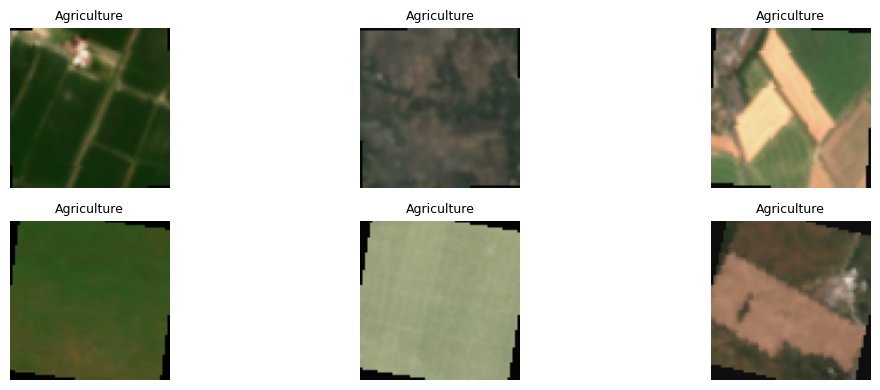

In [ ]:
plt.figure(figsize=(12, 4))
for i in range(6):
    image, label = train_data[i]
    plt.subplot(2, 3, i + 1)
    plt.imshow(image.permute(1, 2, 0))
    plt.title(CLASS_NAMES[label], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

## 7. Define the CNN model

In [ ]:
# 7. Original CNN model and optimizer (no extra pip package required)
class CNNModel(nn.Module):
    def __init__(self, num_classes=19):
        super().__init__()
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3),
            nn.MaxPool2d(2),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.MaxPool2d(2),
            nn.ReLU()
        )
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 256),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.fc_layers(self.conv_layers(x))

model = CNNModel(num_classes=len(CLASS_NAMES)).to(device)
optimizer = Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=MINIMUM_LEARNING_RATE)
criterion = nn.CrossEntropyLoss()

print(model)
print(f'Parameters: {sum(p.numel() for p in model.parameters()):,}')
# Sanity check before training: output must have shape [batch, 19].
with torch.no_grad():
    shape = tuple(model(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)).shape)
assert shape == (1, len(CLASS_NAMES)), f'Unexpected CNN output shape: {shape}'
print('Model output shape:', shape)

CNNModel(
  (conv_layers): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): ReLU()
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): ReLU()
    (6): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): ReLU()
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=6272, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.1, inplace=False)
    (4): Linear(in_features=256, out_features=19, bias=True)
  )
)
Parameters: 1,834,003
Model output shape: (1, 19)


## 8. Training and validation functions

In [ ]:
def train_epoch(model, loader):
    model.train()
    total_loss, correct, total = 0, 0, 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return total_loss / total, correct / total


def validate_epoch(model, loader):
    model.eval()
    total_loss, correct, total = 0, 0, 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

## 9. Train the CNN

In [ ]:
# 9. Train the CNN and save the best validation checkpoint
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

best_val_acc = -1.0
BEST_MODEL_PATH = RESULTS_DIR / 'geosat19_best_cnn.pth'

for epoch in range(EPOCHS):
    current_lr = optimizer.param_groups[0]['lr']
    train_loss, train_acc = train_epoch(model, train_loader)
    val_loss, val_acc = validate_epoch(model, val_loader)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    if val_acc >= best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), BEST_MODEL_PATH)

    print(f'Epoch {epoch + 1}/{EPOCHS} | LR {current_lr:.8f} | '
          f'Train loss {train_loss:.4f}, acc {train_acc:.2%} | '
          f'Val loss {val_loss:.4f}, acc {val_acc:.2%}')

print(f'Best validation accuracy: {best_val_acc:.2%}')
print('Saved best checkpoint to:', BEST_MODEL_PATH)

# Save per-epoch metrics for later analysis.
import csv
with (RESULTS_DIR / 'training_history.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['epoch', 'train_loss', 'train_accuracy', 'val_loss', 'val_accuracy'])
    writer.writerows(zip(range(1, len(train_losses) + 1), train_losses,
                         train_accuracies, val_losses, val_accuracies))
with (RESULTS_DIR / 'settings.json').open('w', encoding='utf-8') as f:
    json.dump({'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
               'minimum_learning_rate': MINIMUM_LEARNING_RATE, 'epochs': EPOCHS,
               'dropout': DROPOUT, 'use_augmentation': USE_AUGMENTATION,
               'max_images_per_class': MAX_IMAGES_PER_CLASS,
               'image_size': IMAGE_SIZE, 'seed': SEED, 'classes': CLASS_NAMES}, f, indent=2)

Epoch 1/25 | LR 0.00300000 | Train loss 2.7121, acc 13.97% | Val loss 2.5620, acc 20.42%
Epoch 2/25 | LR 0.00298821 | Train loss 2.5505, acc 19.92% | Val loss 2.4842, acc 20.98%
Epoch 3/25 | LR 0.00295303 | Train loss 2.4400, acc 23.98% | Val loss 2.3812, acc 24.77%
Epoch 4/25 | LR 0.00289502 | Train loss 2.3864, acc 25.05% | Val loss 2.4060, acc 22.21%
Epoch 5/25 | LR 0.00281508 | Train loss 2.3461, acc 26.39% | Val loss 2.3469, acc 25.75%
Epoch 6/25 | LR 0.00271448 | Train loss 2.2807, acc 27.98% | Val loss 2.3221, acc 27.12%
Epoch 7/25 | LR 0.00259481 | Train loss 2.2661, acc 28.67% | Val loss 2.2653, acc 28.46%
Epoch 8/25 | LR 0.00245795 | Train loss 2.2393, acc 29.38% | Val loss 2.2774, acc 28.60%
Epoch 9/25 | LR 0.00230606 | Train loss 2.1964, acc 30.50% | Val loss 2.2103, acc 31.12%
Epoch 10/25 | LR 0.00214154 | Train loss 2.1563, acc 31.50% | Val loss 2.1856, acc 31.09%
Epoch 11/25 | LR 0.00196698 | Train loss 2.1381, acc 32.08% | Val loss 2.1910, acc 30.60%
Epoch 12/25 | LR 0.

## 10. Plot training and validation curves

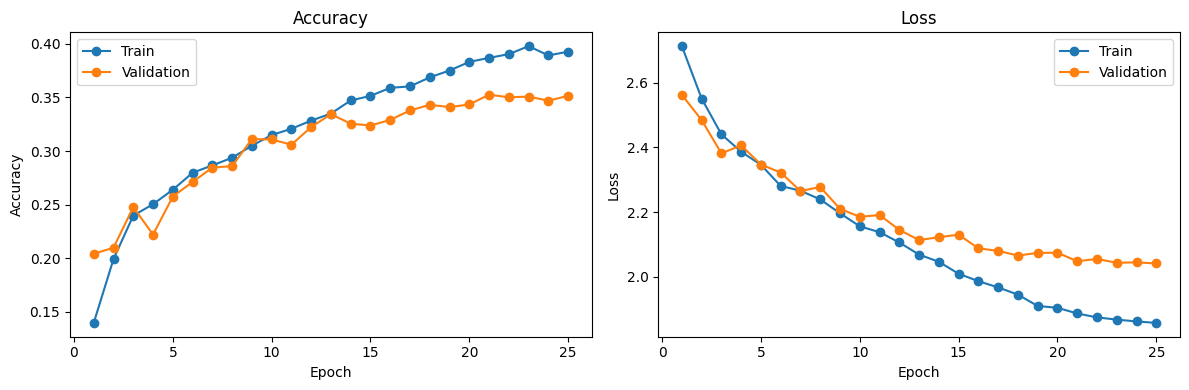

In [ ]:
# 10. Plot / save training and validation accuracy and loss
epoch_numbers = range(1, len(train_accuracies) + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epoch_numbers, train_accuracies, marker='o', label='Train')
plt.plot(epoch_numbers, val_accuracies, marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch_numbers, train_losses, marker='o', label='Train')
plt.plot(epoch_numbers, val_losses, marker='o', label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss')
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'training_curves.png', dpi=180, bbox_inches='tight')
plt.show()

## 11. Test accuracy and confusion matrix

Test accuracy: 34.28%
                    precision    recall  f1-score   support

       Agriculture       0.34      0.57      0.42       150
         Chaparral       0.25      0.16      0.20       150
 Dense Residential       0.50      0.73      0.59       150
            Forest       0.37      0.58      0.45       150
           Freeway       0.28      0.35      0.31       150
       Golf Course       0.24      0.31      0.27       150
            Harbor       0.22      0.16      0.19       150
      Intersection       0.29      0.17      0.21       150
Medium Residential       0.32      0.75      0.45       150
  Mobile Home Park       0.21      0.09      0.13       150
          Overpass       0.27      0.05      0.08       150
       Parking Lot       0.20      0.07      0.11       150
            Quarry       0.40      0.26      0.32       150
           Railway       0.18      0.04      0.07       150
             River       0.42      0.59      0.49       150
            Runwa

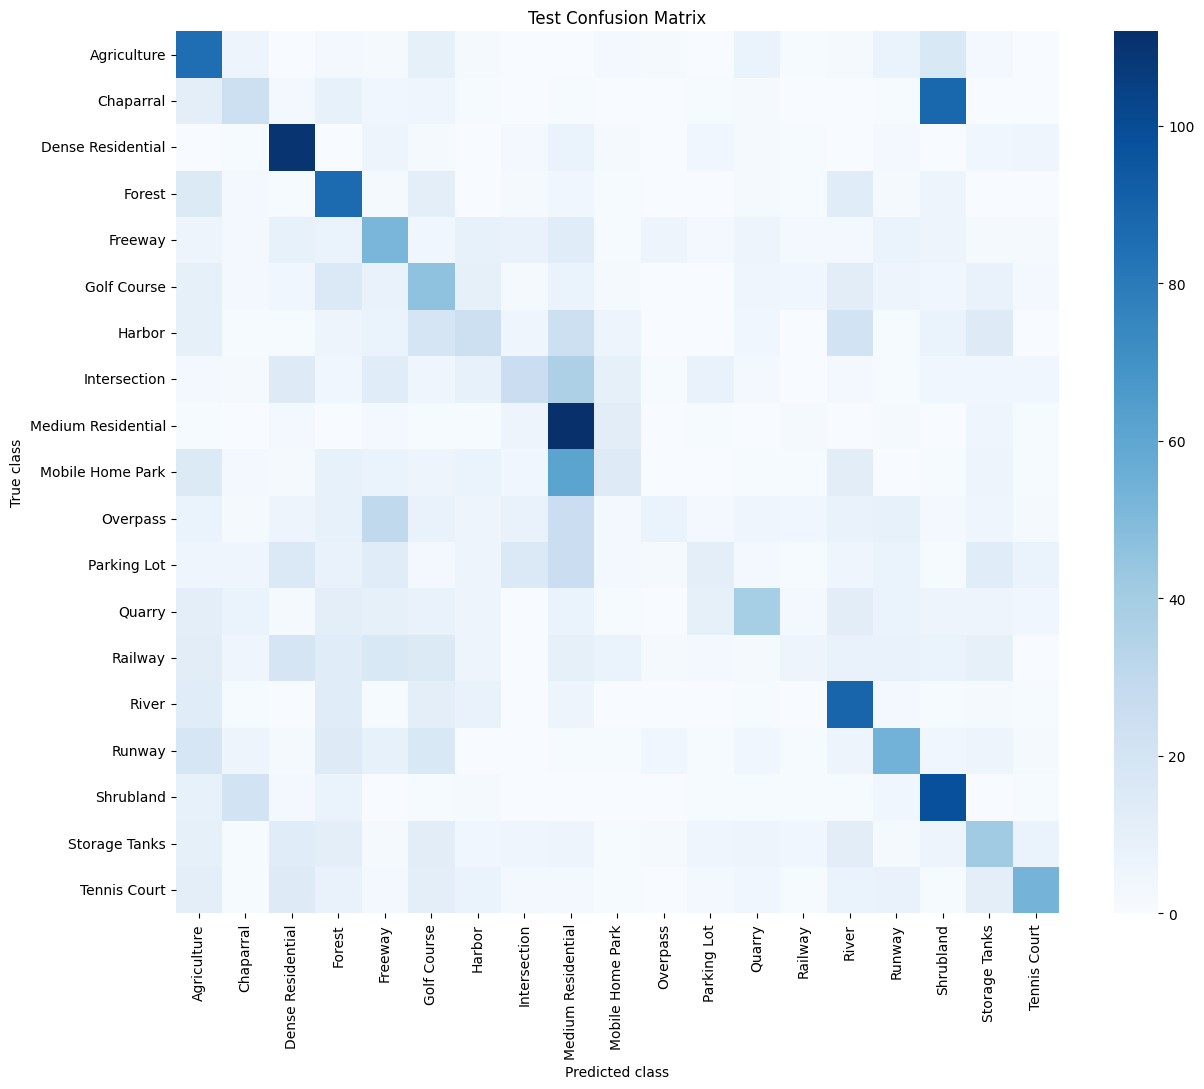

112

In [ ]:
# 11. Evaluate best checkpoint on the held-out test set
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device, weights_only=True))
model.eval()

all_labels, all_preds = [], []
with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        preds = outputs.argmax(1).cpu()
        all_labels.extend(labels.numpy())
        all_preds.extend(preds.numpy())

test_acc = np.mean(np.array(all_labels) == np.array(all_preds))
print(f'Test accuracy: {test_acc:.2%}')
print(classification_report(all_labels, all_preds,
                            labels=list(range(len(CLASS_NAMES))),
                            target_names=CLASS_NAMES, zero_division=0))

cm = confusion_matrix(all_labels, all_preds, labels=range(len(CLASS_NAMES)))
plt.figure(figsize=(13, 11))
sns.heatmap(cm, cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Test Confusion Matrix')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'test_confusion_matrix.png', dpi=180, bbox_inches='tight')
plt.show()

np.savetxt(RESULTS_DIR / 'confusion_matrix.csv', cm, fmt='%d', delimiter=',')
(RESULTS_DIR / 'test_metrics.json').write_text(
    json.dumps({'test_accuracy': float(test_acc), 'num_test_images': len(all_labels),
                'best_val_accuracy': float(best_val_acc)}, indent=2), encoding='utf-8')

## 12. Show predictions for six test images

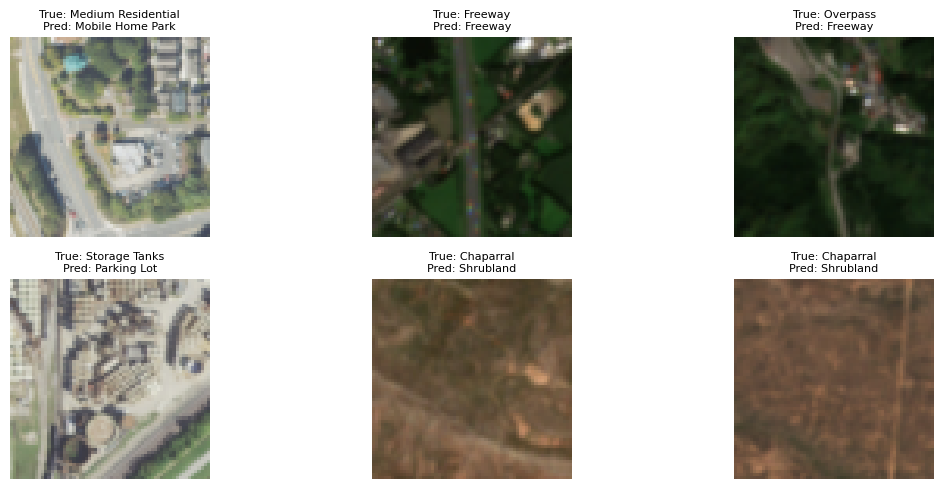

In [ ]:
rng = random.Random(7)
selected = rng.sample(range(len(test_data)), min(6, len(test_data)))

plt.figure(figsize=(12, 5))
model.eval()
with torch.no_grad():
    for i, index in enumerate(selected):
        image, actual = test_data[index]
        output = model(image.unsqueeze(0).to(device))
        predicted = output.argmax(1).item()

        plt.subplot(2, 3, i + 1)
        plt.imshow(image.permute(1, 2, 0))
        plt.title(f'True: {CLASS_NAMES[actual]}\nPred: {CLASS_NAMES[predicted]}', fontsize=8)
        plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# 13. Archive results in Google Drive (with optional local download)
archive_base = RESULTS_DIR.parent / 'GeoSat19_Results_Archive'
archive_path = Path(shutil.make_archive(str(archive_base), 'zip', root_dir=RESULTS_DIR))
print('Results saved to Google Drive:', RESULTS_DIR)
print('ZIP archive saved to Google Drive:', archive_path)

if DOWNLOAD_RESULTS_ZIP:
    from google.colab import files
    files.download(str(archive_path))
else:
    print('No download required; the outputs are already in your Google Drive.')


Results saved to Google Drive: /content/drive/MyDrive/GeoSat19_Results
ZIP archive saved to Google Drive: /content/drive/MyDrive/GeoSat19_Results_Archive.zip
No download required; the outputs are already in your Google Drive.
